Wczytano obraz o wymiarach: torch.Size([1, 1, 521, 588])


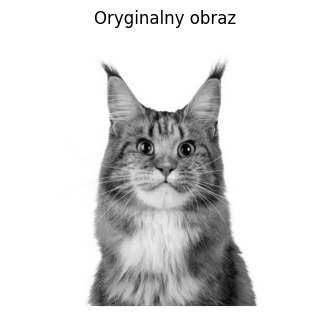

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet18, ResNet18_Weights
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

img_path = 'kot_11.jpg'
try:
    pil_img = Image.open(img_path).convert('L')
    img_tensor = torch.from_numpy(np.array(pil_img)).float().unsqueeze(0).unsqueeze(0) / 255.0
    print(f"Wczytano obraz o wymiarach: {img_tensor.shape}")

    plt.figure(figsize=(4, 4))
    plt.imshow(img_tensor[0, 0], cmap='gray')
    plt.title("Oryginalny obraz")
    plt.axis('off')
    plt.show()
except FileNotFoundError:
    print(f"Proszę wgrać plik {img_path} do środowiska Colab.")
    img_tensor = torch.rand(1, 1, 224, 224)

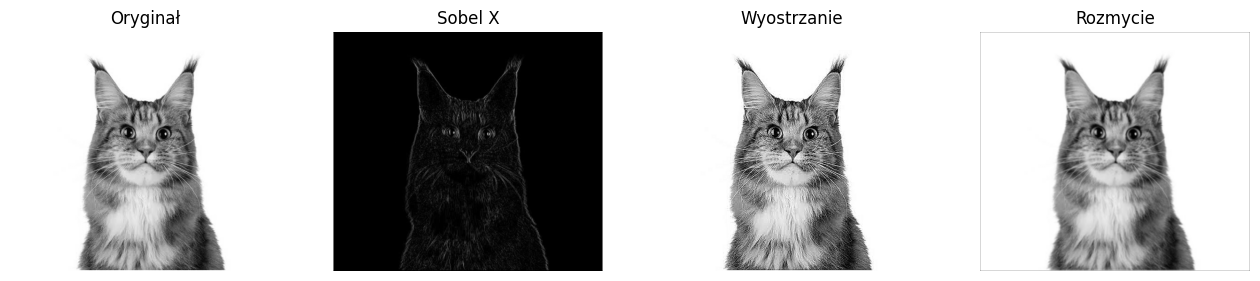

In [2]:
def create_kernel(weights):
    return torch.tensor(weights, dtype=torch.float32).unsqueeze(0).unsqueeze(0)

sobel_x = create_kernel([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
sharpen = create_kernel([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
blur = torch.ones(1, 1, 3, 3) / 9.0

out_sobel = F.conv2d(img_tensor, sobel_x, padding=1)
out_sharpen = F.conv2d(img_tensor, sharpen, padding=1)
out_blur = F.conv2d(img_tensor, blur, padding=1)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(img_tensor[0, 0], cmap='gray'); axes[0].set_title("Oryginał"); axes[0].axis('off')
axes[1].imshow(out_sobel[0, 0].abs(), cmap='gray'); axes[1].set_title("Sobel X"); axes[1].axis('off')
axes[2].imshow(out_sharpen[0, 0].clamp(0, 1), cmap='gray'); axes[2].set_title("Wyostrzanie"); axes[2].axis('off')
axes[3].imshow(out_blur[0, 0], cmap='gray'); axes[3].set_title("Rozmycie"); axes[3].axis('off')
plt.show()

In [3]:
def calc_out_dim(in_size, k, s, p, d):
    return (in_size + 2*p - d*(k-1) - 1) // s + 1

IN_SIZE = img_tensor.shape[-1]
combinations = [
    {"k": 3, "s": 1, "p": 1, "d": 1},
    {"k": 5, "s": 2, "p": 2, "d": 1},
    {"k": 3, "s": 1, "p": 2, "d": 2},
    {"k": 7, "s": 3, "p": 0, "d": 1},
    {"k": 5, "s": 1, "p": 4, "d": 2}
]

print("--- Wzór na wymiary ---")
print(f"{'k':>2} | {'s':>2} | {'p':>2} | {'d':>2} | {'Wzór':>6} | {'Conv2d':>6} | {'Status':>6}")
print("-" * 45)

for c in combinations:
    formula_out = calc_out_dim(IN_SIZE, c['k'], c['s'], c['p'], c['d'])
    conv = nn.Conv2d(1, 1, kernel_size=c['k'], stride=c['s'], padding=c['p'], dilation=c['d'])
    real_out = conv(img_tensor).shape[-1]
    status = "OK" if formula_out == real_out else "BŁĄD"
    print(f"{c['k']:2d} | {c['s']:2d} | {c['p']:2d} | {c['d']:2d} | {formula_out:6d} | {real_out:6d} | {status:>6}")

--- Wzór na wymiary ---
 k |  s |  p |  d |   Wzór | Conv2d | Status
---------------------------------------------
 3 |  1 |  1 |  1 |    588 |    588 |     OK
 5 |  2 |  2 |  1 |    294 |    294 |     OK
 3 |  1 |  2 |  2 |    588 |    588 |     OK
 7 |  3 |  0 |  1 |    194 |    194 |     OK
 5 |  1 |  4 |  2 |    588 |    588 |     OK


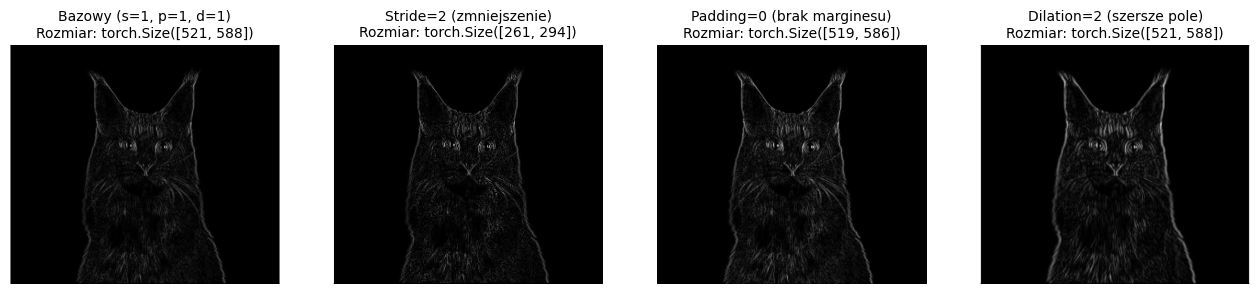

In [4]:
settings = [
    {"s": 1, "p": 1, "d": 1, "name": "Bazowy (s=1, p=1, d=1)"},
    {"s": 2, "p": 1, "d": 1, "name": "Stride=2 (zmniejszenie)"},
    {"s": 1, "p": 0, "d": 1, "name": "Padding=0 (brak marginesu)"},
    {"s": 1, "p": 2, "d": 2, "name": "Dilation=2 (szersze pole)"}
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, cfg in zip(axes, settings):
    out = F.conv2d(img_tensor, sobel_x, stride=cfg['s'], padding=cfg['p'], dilation=cfg['d'])
    ax.imshow(out[0, 0].abs(), cmap='gray')
    ax.set_title(f"{cfg['name']}\nRozmiar: {out.shape[-2:]}", fontsize=10)
    ax.axis('off')
plt.show()

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 136MB/s]


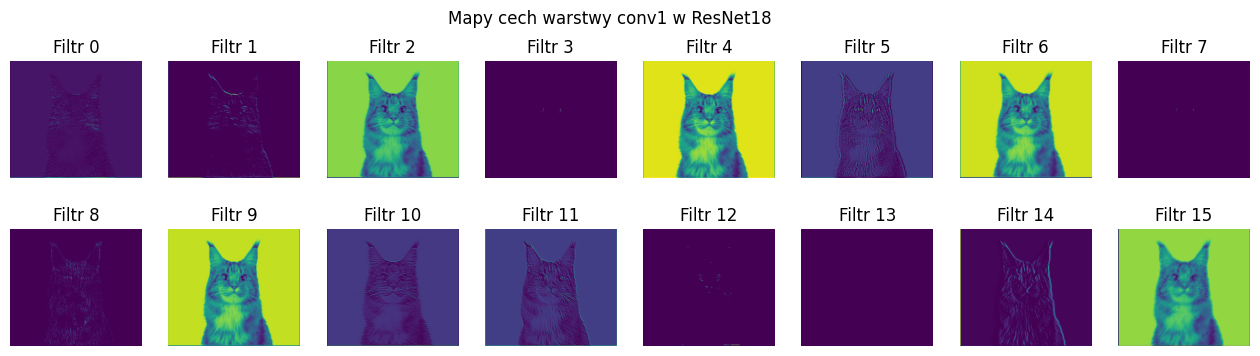

In [5]:
img_3ch = img_tensor.repeat(1, 3, 1, 1)
model = resnet18(weights=ResNet18_Weights.DEFAULT)
model.eval()

with torch.no_grad():
    feature_maps = model.conv1(img_3ch)[0]

fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i, ax in enumerate(axes.flat):
    fmap = torch.relu(feature_maps[i]).numpy()
    ax.imshow(fmap, cmap='viridis')
    ax.set_title(f"Filtr {i}")
    ax.axis('off')
plt.suptitle("Mapy cech warstwy conv1 w ResNet18")
plt.show()

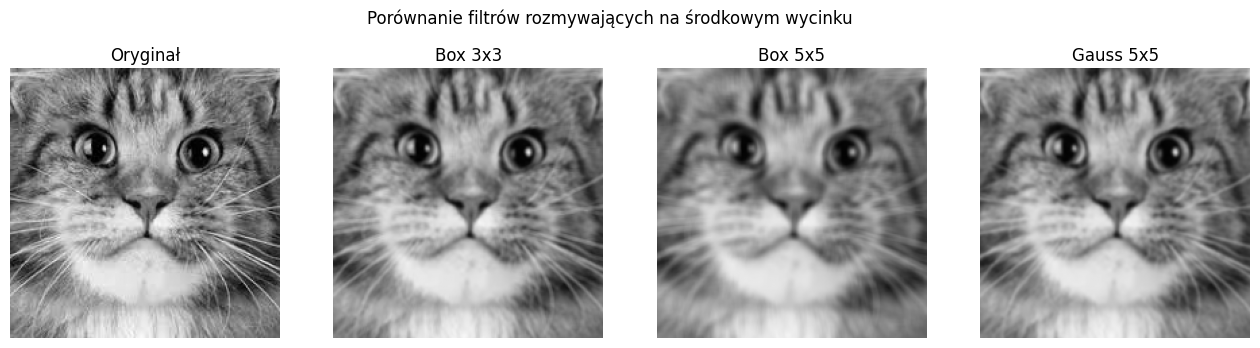

In [8]:
box_3x3 = torch.ones(1, 1, 3, 3) / 9.0
box_5x5 = torch.ones(1, 1, 5, 5) / 25.0

gauss_weights = [
    [1,  4,  7,  4, 1],
    [4, 16, 26, 16, 4],
    [7, 26, 41, 26, 7],
    [4, 16, 26, 16, 4],
    [1,  4,  7,  4, 1]
]
gauss_5x5 = create_kernel(gauss_weights) / 273.0

out_box3 = F.conv2d(img_tensor, box_3x3, padding=1)
out_box5 = F.conv2d(img_tensor, box_5x5, padding=2)
out_gauss5 = F.conv2d(img_tensor, gauss_5x5, padding=2)

# Dynamiczne pobieranie środka obrazu w celu uzyskania szczegółów i krawędzi
h, w = img_tensor.shape[-2], img_tensor.shape[-1]
cy, cx = h // 2, w // 2
crop_size = 100
crop = slice(cy - crop_size, cy + crop_size), slice(cx - crop_size, cx + crop_size)

crops = {
    "Oryginał": img_tensor[0, 0][crop].numpy(),
    "Box 3x3": out_box3[0, 0][crop].numpy(),
    "Box 5x5": out_box5[0, 0][crop].numpy(),
    "Gauss 5x5": out_gauss5[0, 0][crop].numpy()
}

vmin = min(c.min() for c in crops.values())
vmax = max(c.max() for c in crops.values())

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (name, img_crop) in zip(axes, crops.items()):
    ax.imshow(img_crop, cmap='gray', vmin=vmin, vmax=vmax)
    ax.set_title(name)
    ax.axis('off')
plt.suptitle("Porównanie filtrów rozmywających na środkowym wycinku")
plt.show()